In [1]:
import pandas as pd # Import pandas for data handling
import numpy as np # Import numpy for numerical calculations
import matplotlib.pyplot as plt # Import matplotlib for plotting
import seaborn as sns # Import seaborn for visualization
from sklearn.model_selection import train_test_split # Import function to split data
from sklearn.neighbors import KNeighborsClassifier # Import K-Nearest Neighbors classifier
from sklearn.svm import SVC # Import Support Vector Machine classifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix # Import evaluation metrics


In [18]:
df = pd.read_csv(r"C:\Users\prath\Desktop\SEM 7\LP3\ML\Datasets\emails.csv")
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (5172, 3002)


,Email No.,the,to,ect,and,for,of,a,you,hou,...,connevey,jay,valued,lay,infrastructure,military,allowing,ff,dry,Prediction
0,Email 1,0,0,1,0,0,0,2,0,0,...,0,0,0,0,0,0,0,0,0,0
1,Email 2,8,13,24,6,6,2,102,1,27,...,0,0,0,0,0,0,0,1,0,0
2,Email 3,0,0,1,0,0,0,8,0,0,...,0,0,0,0,0,0,0,0,0,0
3,Email 4,0,5,22,0,5,1,51,2,10,...,0,0,0,0,0,0,0,0,0,0
4,Email 5,7,6,17,1,5,2,57,0,9,...,0,0,0,0,0,0,0,1,0,0


In [10]:
if "Email No." in df.columns:                            # Check if Email No. column exists
    df = df.drop(columns=["Email No."])  
df["Prediction"] = df["Prediction"].astype(int)          # Convert target values to integers

X = df.drop(columns=["Prediction"])                      # Store input features
y = df["Prediction"]                                     # Store target variable

print(df.columns)                                        # Display column names
print(df.head(5))# Remove unnecessary email number column

Index(['the', 'to', 'ect', 'and', 'for', 'of', 'a', 'you', 'hou', 'in',
       ...
       'connevey', 'jay', 'valued', 'lay', 'infrastructure', 'military',
       'allowing', 'ff', 'dry', 'Prediction'],
      dtype='object', length=3001)
   the  to  ect  and  for  of    a  you  hou  in  ...  connevey  jay  valued  \
0    0   0    1    0    0   0    2    0    0   0  ...         0    0       0   
1    8  13   24    6    6   2  102    1   27  18  ...         0    0       0   
2    0   0    1    0    0   0    8    0    0   4  ...         0    0       0   
3    0   5   22    0    5   1   51    2   10   1  ...         0    0       0   
4    7   6   17    1    5   2   57    0    9   3  ...         0    0       0   

   lay  infrastructure  military  allowing  ff  dry  Prediction  
0    0               0         0         0   0    0           0  
1    0               0         0         0   1    0           0  
2    0               0         0         0   0    0           0  
3    0           

In [11]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
the           0
to            0
ect           0
and           0
for           0
             ..
military      0
allowing      0
ff            0
dry           0
Prediction    0
Length: 3001, dtype: int64


In [12]:
print(df.columns.tolist())

['the', 'to', 'ect', 'and', 'for', 'of', 'a', 'you', 'hou', 'in', 'on', 'is', 'this', 'enron', 'i', 'be', 'that', 'will', 'have', 'with', 'your', 'at', 'we', 's', 'are', 'it', 'by', 'com', 'as', 'from', 'gas', 'or', 'not', 'me', 'deal', 'if', 'meter', 'hpl', 'please', 're', 'e', 'any', 'our', 'corp', 'can', 'd', 'all', 'has', 'was', 'know', 'need', 'an', 'forwarded', 'new', 't', 'may', 'up', 'j', 'mmbtu', 'should', 'do', 'am', 'get', 'out', 'see', 'no', 'there', 'price', 'daren', 'but', 'been', 'company', 'l', 'these', 'let', 'so', 'would', 'm', 'into', 'xls', 'farmer', 'attached', 'us', 'information', 'they', 'message', 'day', 'time', 'my', 'one', 'what', 'only', 'http', 'th', 'volume', 'mail', 'contract', 'which', 'month', 'more', 'robert', 'sitara', 'about', 'texas', 'nom', 'energy', 'pec', 'questions', 'www', 'deals', 'volumes', 'pm', 'ena', 'now', 'their', 'file', 'some', 'email', 'just', 'also', 'call', 'change', 'other', 'here', 'like', 'b', 'flow', 'net', 'following', 'p', 'pro

In [13]:
X_train, X_test, y_train, y_test = train_test_split(     # Split data into training and testing sets
    X,                                                    # Input features
    y,                                                    # Target labels
    test_size=0.2,                                        # Use 20% data for testing
    random_state=42,                                      # Make results reproducible
    stratify=y                                             # Keep class proportions balanced
)

print("Training samples:", X_train.shape[0])             # Display training sample count
print("Testing samples:", X_test.shape[0])               # Display testing sample count

Training samples: 4137
Testing samples: 1035


In [14]:
knn = KNeighborsClassifier(n_neighbors=5)                # Create KNN model using 5 neighbors

knn.fit(X_train, y_train)                                # Train the KNN model

y_pred_knn = knn.predict(X_test)                         # Predict classes for test data

print("\n--- KNN Performance ---")                        # Display KNN heading

print("Accuracy:", accuracy_score(y_test, y_pred_knn))   # Calculate and display accuracy

print("Classification Report:\n",                       # Display classification report
      classification_report(y_test, y_pred_knn))          # Calculate precision, recall and F1-score

print("Confusion Matrix:\n",                             # Display confusion matrix heading
      confusion_matrix(y_test, y_pred_knn))              # Calculate confusion matrix


--- KNN Performance ---
Accuracy: 0.8714975845410629
Classification Report:
               precision    recall  f1-score   support

           0       0.93      0.88      0.91       735
           1       0.74      0.85      0.79       300

    accuracy                           0.87      1035
   macro avg       0.84      0.86      0.85      1035
weighted avg       0.88      0.87      0.87      1035

Confusion Matrix:
 [[648  87]
 [ 46 254]]


In [15]:
svm = SVC(kernel="linear", random_state=42)              # Create SVM using a linear kernel

svm.fit(X_train, y_train)                                # Train the SVM model

y_pred_svm = svm.predict(X_test)                         # Predict classes for test data

print("\n--- SVM Performance ---")                        # Display SVM heading

print("Accuracy:", accuracy_score(y_test, y_pred_svm))   # Calculate and display accuracy

print("Classification Report:\n",                       # Display classification report
      classification_report(y_test, y_pred_svm))          # Calculate precision, recall and F1-score

print("Confusion Matrix:\n",                             # Display confusion matrix heading
      confusion_matrix(y_test, y_pred_svm))              # Calculate confusion matrix


--- SVM Performance ---
Accuracy: 0.9671497584541063
Classification Report:
               precision    recall  f1-score   support

           0       0.98      0.97      0.98       735
           1       0.94      0.95      0.94       300

    accuracy                           0.97      1035
   macro avg       0.96      0.96      0.96      1035
weighted avg       0.97      0.97      0.97      1035

Confusion Matrix:
 [[716  19]
 [ 15 285]]


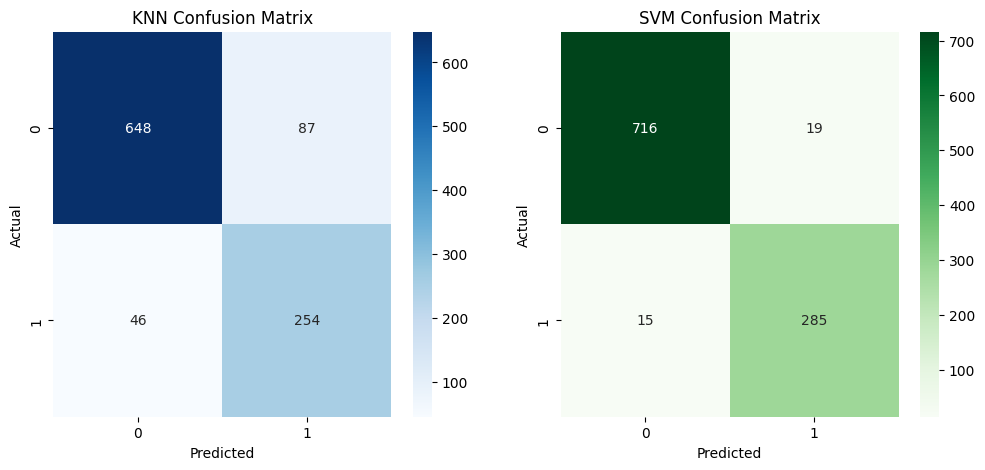

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))            # Create two plots side by side

sns.heatmap(                                              # Create KNN heatmap
    confusion_matrix(y_test, y_pred_knn),                 # Generate KNN confusion matrix
    annot=True,                                           # Display values inside cells
    fmt="d",                                              # Display values as integers
    cmap="Blues",                                         # Use blue color map
    ax=ax[0]                                              # Place graph on first axis
)

ax[0].set_title("KNN Confusion Matrix")                   # Set KNN graph title
ax[0].set_xlabel("Predicted")                            # Label x-axis
ax[0].set_ylabel("Actual")                               # Label y-axis

sns.heatmap(                                              # Create SVM heatmap
    confusion_matrix(y_test, y_pred_svm),                 # Generate SVM confusion matrix
    annot=True,                                           # Display values inside cells
    fmt="d",                                              # Display values as integers
    cmap="Greens",                                        # Use green color map
    ax=ax[1]                                              # Place graph on second axis
)

ax[1].set_title("SVM Confusion Matrix")                   # Set SVM graph title
ax[1].set_xlabel("Predicted")                            # Label x-axis
ax[1].set_ylabel("Actual")                               # Label y-axis

plt.show()                                               # Display both graphs

In [17]:
knn_accuracy = accuracy_score(y_test, y_pred_knn)        # Calculate KNN accuracy

svm_accuracy = accuracy_score(y_test, y_pred_svm)        # Calculate SVM accuracy

print("KNN Accuracy:", knn_accuracy)                     # Display KNN accuracy

print("SVM Accuracy:", svm_accuracy)                     # Display SVM accuracy

if svm_accuracy > knn_accuracy:                           # Check if SVM has higher accuracy
    print("SVM performs better than KNN")                 # Display better model
else:                                                     # Otherwise
    print("KNN performs better than SVM")                 # Display better model

KNN Accuracy: 0.8714975845410629
SVM Accuracy: 0.9671497584541063
SVM performs better than KNN


In [ ]:
'''
What type of machine learning problem is this?
Answer: It is a supervised binary classification problem.

What is binary classification?
Answer: Classification into two classes. - 0 → Not Spam - 1 → Spam

What is the target variable?
Answer: Prediction is the target variable.

Prediction = 0 (The email is Not Spam.) Prediction = 1 (The email is Spam.)'

don't we use TF-IDF in this code?
Answer: Because this dataset is already converted into numerical word-frequency features.

Why can't we directly give text to KNN or SVM?
Answer: Machine learning algorithms require numerical input, so text must be converted into numerical features.

What is KNN?
Answer: KNN stands for K-Nearest Neighbors. It classifies a data point based on its nearest neighboring points.

KNN work?
Answer: It finds the K nearest data points and assigns the class based on majority voting.

K_value = 5

one disadvantage of KNN?
Answer: It can be slow for large datasets because it calculates distances to many data points.

What is SVM?
Answer: SVM stands for Support Vector Machine. It finds the best boundary to separate different classes.

What is a hyperplane?
Answer: A hyperplane is a decision boundary that separates classes.

Which kernel did we use?
Answer: We used a linear kernel.Because the dataset has many numerical features and a linear boundary works well for this classification problem

What are support vectors?
Answer: They are the data points closest to the decision boundary.

SVM suitable for this dataset?
Answer: SVM works well with high-dimensional data, such as our 3000 features.

confusion matrix?
Answer: It shows the number of correct and incorrect predictions for each class.

Why did SVM perform better?
Answer: SVM is more suitable for this high-dimensional dataset and was able to separate Spam and Not Spam more effectively.

